# Lecture 3: two players, two inspected updates

Slides: [Lecture 3 at a glance](https://nipunbatra.github.io/generative/lectures/lecture3/#contents/1)

**Prediction first:** what should change in each phase? This notebook executes the scalar arithmetic, checks neural parameter ownership, runs a short CPU toy experiment and replays the saved MNIST generator. It does not silently retrain the image GAN.

Data: the toy is an equal mixture N(−2,0.5²), N(2,0.5²). Images are greyscale MNIST rescaled to [−1,1]. Discriminator losses are mean(real BCE) + mean(fake BCE); generator loss is mean(fake BCE with target1). All logarithms are natural.

In [1]:
from pathlib import Path
import sys, time, json, copy, os
ROOT = Path.cwd()
if not (ROOT / "scripts/gan.py").exists():
    ROOT = ROOT / "generative-series/lecture3"
sys.path.insert(0, str(ROOT / "scripts"))
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from gan import ConvG, ConvD, train_toy_gan
from prepare import scalar_updates
get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(2)
torch.manual_seed(667)
print("torch", torch.__version__, "device: cpu")

torch 2.13.0 device: cpu


## 1. One scalar D update, then one scalar G update

Slides: [2.1 Data, labels and two small networks](https://nipunbatra.github.io/generative/lectures/lecture3/#data-labels/1) · [2.2 The discriminator’s loss](https://nipunbatra.github.io/generative/lectures/lecture3/#d-real-term/1) · [2.3 One D update, then check](https://nipunbatra.github.io/generative/lectures/lecture3/#d-gradient/1) · [3.1 The generator’s goal](https://nipunbatra.github.io/generative/lectures/lecture3/#g-goal/1) · [3.2 One G update, then check](https://nipunbatra.github.io/generative/lectures/lecture3/#g-gradient/1)

Choose G(z)=az+b with a=.5,b=−.5,z=1 and D(x)=sigmoid(wx+c) with w=.4,c=−.2. One real example is x=2. **Predict:** which four parameter values change in which phase?

In [2]:
checked = scalar_updates()
for key in ["before", "dGradient", "afterD", "gGradient", "afterG"]:
    print(key, checked[key])
assert checked["afterD"]["a"] == checked["before"]["a"]
assert checked["afterG"]["w"] == checked["afterD"]["w"]
print("G derivative finite-difference residual:",
      abs(checked["gGradient"]["a"]-checked["gFiniteDifference"]))

before {'a': 0.5, 'b': -0.5, 'w': 0.4, 'c': -0.2, 'fake': 0.0, 'real': 2.0, 'z': 1.0, 'Dreal': 0.6456563062257954, 'Dfake': 0.45016600268752216, 'lossD': 1.0356268198674774}
dGradient {'w': -0.708687387548409, 'c': 0.09582230891331761, 'a': None, 'b': None}
afterD {'w': 0.4708687387548409, 'c': -0.20958223089133177, 'a': 0.5, 'b': -0.5, 'lossD': 0.9864673840195968, 'Dreal': 0.6752780483169097, 'Dfake': 0.4477953918934189}
gGradient {'a': -0.2600158873537571, 'b': -0.2600158873537571}
afterG {'a': 0.5260015887353757, 'b': -0.4739984112646243, 'w': 0.4708687387548409, 'c': -0.20958223089133177, 'fake': 0.05200317747075145, 'lossG': 0.7899714070451374}
G derivative finite-difference residual: 2.2917390207766175e-11


The D loss falls on the same two fixed examples. The G loss falls against the same updated, fixed discriminator. Neither comparison establishes global convergence. The derivative check holds z and the real input fixed.

In [3]:
p_real = checked["before"]["Dreal"]
p_fake = checked["before"]["Dfake"]
manual_D = -np.log(p_real)-np.log1p(-p_fake)
logits = torch.tensor([.6, -.2], dtype=torch.float64)
stable_D = F.binary_cross_entropy_with_logits(logits, torch.tensor([1.,0.],dtype=torch.float64), reduction="sum")
assert abs(manual_D-float(stable_D)) < 1e-12
print("probability arithmetic / stable-logit BCE:", manual_D, float(stable_D))

probability arithmetic / stable-logit BCE: 1.0356268198674776 1.0356268198674776


## 2. Two neural updates with parameter ownership checks

Slides: [2.4 Detach the fake](https://nipunbatra.github.io/generative/lectures/lecture3/#detach/1) · [4.3 One neural update](https://nipunbatra.github.io/generative/lectures/lecture3/#alternating-code-d/1)

This small MLP has no BatchNorm buffers or dropout. We clear gradients before inspecting them and compare parameters before/after the actual optimiser step. A nonzero stale `.grad` is not evidence that a phase changed a parameter.

In [4]:
def checked_neural_step():
    torch.manual_seed(667)
    G = nn.Sequential(nn.Linear(1,8), nn.Tanh(), nn.Linear(8,1))
    D = nn.Sequential(nn.Linear(1,8), nn.Tanh(), nn.Linear(8,1))
    optG = torch.optim.SGD(G.parameters(), lr=.05)
    optD = torch.optim.SGD(D.parameters(), lr=.05)
    real = torch.tensor([[-2.],[-1.8],[1.7],[2.2]])
    z = torch.tensor([[-1.],[-.3],[.2],[1.]])
    snapshot = lambda M: [p.detach().clone() for p in M.parameters()]
    change = lambda M, old: max(float((p.detach()-a).abs().max()) for p,a in zip(M.parameters(),old))
    g0,d0 = snapshot(G),snapshot(D)
    optG.zero_grad(set_to_none=True); optD.zero_grad(set_to_none=True)
    fake = G(z)
    lossD = F.softplus(-D(real)).mean() + F.softplus(D(fake.detach())).mean()
    lossD.backward()
    assert all(p.grad is None for p in G.parameters())
    optD.step()
    g_in_D,d_in_D = change(G,g0),change(D,d0)
    assert g_in_D == 0 and d_in_D > 0
    g0,d0 = snapshot(G),snapshot(D)
    optD.zero_grad(set_to_none=True); D.requires_grad_(False)
    optG.zero_grad(set_to_none=True)
    lossG = F.softplus(-D(G(z))).mean()
    lossG.backward()
    assert any(p.grad.abs().sum() > 0 for p in G.parameters())
    assert all(p.grad is None for p in D.parameters())
    optG.step(); D.requires_grad_(True)
    g_in_G,d_in_G = change(G,g0),change(D,d0)
    assert g_in_G > 0 and d_in_G == 0
    return dict(G_change_in_D=g_in_D,D_change_in_D=d_in_D,
                G_change_in_G=g_in_G,D_change_in_G=d_in_G,
                lossD=float(lossD.detach()),lossG=float(lossG.detach()))
checks = checked_neural_step()
print(checks)

{'G_change_in_D': 0.0, 'D_change_in_D': 0.0118541419506073, 'G_change_in_G': 0.0002359151840209961, 'D_change_in_G': 0.0, 'lossD': 1.5138671398162842, 'lossG': 0.6461316347122192}


### Why freezing is different from detaching

Slides: [3.3 Freeze versus detach](https://nipunbatra.github.io/generative/lectures/lecture3/#g-code/1)

Freezing D weights keeps its input derivative. Detaching G(z) cuts the path to G. `torch.no_grad()` around D also cuts the path. Test the wrong version safely; a failure is caught and explained.

In [5]:
G = nn.Linear(1,1); D = nn.Linear(1,1)
D.requires_grad_(False)
z = torch.ones(1,1)
good = F.softplus(-D(G(z)))
good.backward()
print("G receives a gradient through frozen D:", G.weight.grad)
bad = F.softplus(-D(G(z).detach()))
print("Detached result requires grad:", bad.requires_grad)
assert not bad.requires_grad
try:
    bad.backward()
except RuntimeError as error:
    print("Expected: backward has no path to trainable values.")

G receives a gradient through frozen D: tensor([[-0.1283]])
Detached result requires grad: False
Expected: backward has no path to trainable values.


## 3. A short CPU experiment

Slides: [1.2 Two players](https://nipunbatra.github.io/generative/lectures/lecture3/#toy-vote/1) · [4.1 The training loop](https://nipunbatra.github.io/generative/lectures/lecture3/#alternating/1) · [4.2 Minimax and saturation](https://nipunbatra.github.io/generative/lectures/lecture3/#minimax/1)

This is a **fresh 400-update run**, not the saved 3,000-update lecture evidence. Inspect the generated distribution; do not assume the quick run has converged. KDE smoothness and histogram bins change the picture, not the samples.

CPU seconds: 0.3038168328348547
mass near left / right: 0.512 0.4395


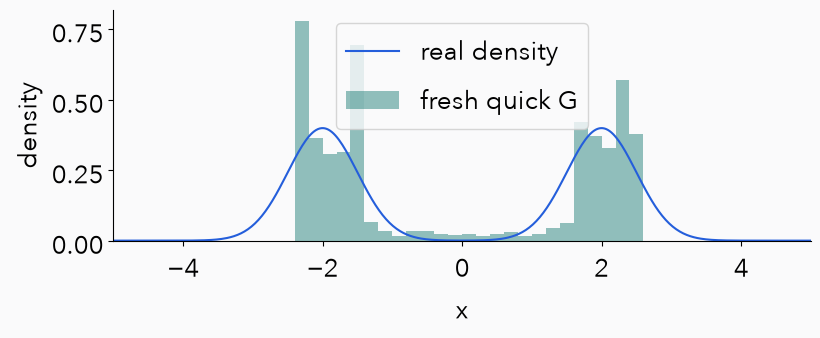

In [6]:
start=time.perf_counter()
quick = train_toy_gan(seed=4, steps=400)
print("CPU seconds:", time.perf_counter()-start)
print("mass near left / right:", quick["left"], quick["right"])
fig,ax=plt.subplots(figsize=(9,3))
x=np.linspace(-5,5,400)
p=(np.exp(-.5*((x-2)/.5)**2)+np.exp(-.5*((x+2)/.5)**2))/(np.sqrt(2*np.pi))
ax.plot(x,p,label="real density",color="#245EDB")
ax.hist(quick["record"][400]["samples"],bins=50,range=(-5,5),density=True,alpha=.45,color="#0F766E",label="fresh quick G")
ax.set(xlim=(-5,5),xlabel="x",ylabel="density");ax.legend();plt.show()

## 4. Inspect the existing stable and collapsed runs

Slides: [5.1 Coverage and collapse](https://nipunbatra.github.io/generative/lectures/lecture3/#coverage/1) · [5.2 What a loss curve cannot tell](https://nipunbatra.github.io/generative/lectures/lecture3/#losses-not-quality/1)

The lecture reuses measured 3,000-update runs from the focused GAN material. Width64/seed4 and width4/seed0 differ in both capacity and seed; this comparison demonstrates a failure, not a controlled causal claim that width alone determines collapse.

wide saved run {'seed': 4, 'steps': 3000, 'left': 0.518, 'right': 0.4605}
narrow saved run {'seed': 0, 'steps': 3000, 'left': 0.9485, 'right': 0.0}


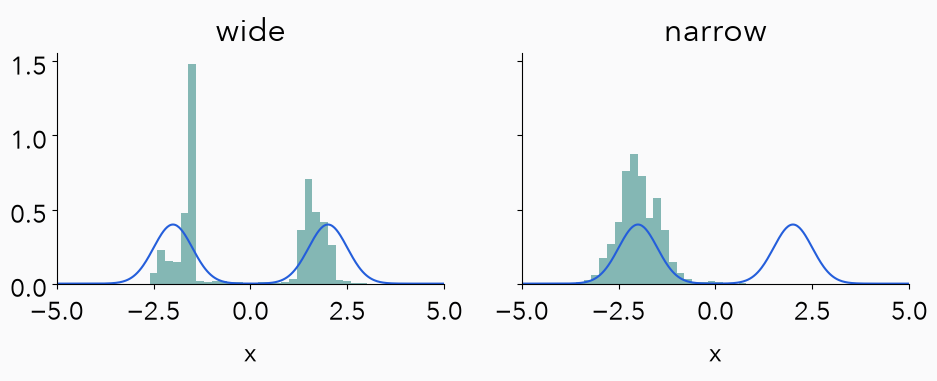

In [7]:
stable=json.loads((ROOT/"data/toy_gan_runs.json").read_text())[4]
collapsed=json.loads((ROOT/"data/toy_gan_collapse.json").read_text())
for label,r in [("wide saved run",stable),("narrow saved run",collapsed)]:
    print(label, {k:r[k] for k in ["seed","steps","left","right"]})
fig,axes=plt.subplots(1,2,figsize=(11,3),sharex=True,sharey=True)
for ax,(label,r) in zip(axes,[("wide",stable),("narrow",collapsed)]):
    ax.plot(x,p,color="#245EDB")
    ax.hist(r["record"]["3000"]["samples"],bins=50,range=(-5,5),density=True,color="#0F766E",alpha=.5)
    ax.set(title=label,xlim=(-5,5),xlabel="x")
plt.show()

## 5. Replay the trained image generator

Slides: [1.1 A generator needs feedback](https://nipunbatra.github.io/generative/lectures/lecture3/#start/1) · [6.1 Images in and out](https://nipunbatra.github.io/generative/lectures/lecture3/#image-representation/1) · [6.2 Training on MNIST](https://nipunbatra.github.io/generative/lectures/lecture3/#image-training-early/1)

The saved MNIST run used 30 epochs, seed1 and latent dimension100. The checkpoint is copied unchanged with a SHA-256 provenance record. This cell runs G locally; it does not display invented training output. Grey pixels are distinct from the binary Bernoulli VAE convention.

maximum replay difference: 5.275011e-06


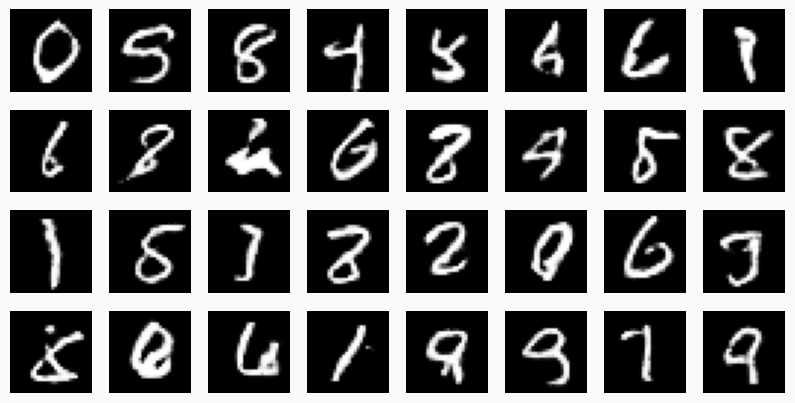

In [8]:
saved=torch.load(ROOT/"models/gan_mnist.pt",map_location="cpu",weights_only=True)
G=ConvG();G.load_state_dict(saved["G"]);G.eval()
z=torch.randn(64,100,generator=torch.Generator().manual_seed(123))
with torch.no_grad():
    samples=(G(z)[:,0].numpy()+1)/2
original=np.load(ROOT/"data/gan_mnist_snapshots.npz")["30"]
error=np.abs(samples-original).max()
assert error < 2e-5
print("maximum replay difference:",error)
fig,axes=plt.subplots(4,8,figsize=(10,5))
for ax,img in zip(axes.flat,samples):
    ax.imshow(img,cmap="gray",vmin=0,vmax=1);ax.axis("off")
plt.show()

## 6. Optional full training

Leave `RUN_FULL=False` for the short classroom route. To reproduce full training, set `MNIST_ROOT` to the directory **containing `MNIST/raw`**, use the original complete MNIST training split and enable this cell. No download is attempted. CPU is supported but slower; set `gan.DEVICE="mps"` only if available. This writes a new model under `models/full-retrain/`, preserving the supplied checkpoint. The original full run’s measured settings are in `data/original-training.json`.

In [9]:
RUN_FULL = False
if RUN_FULL:
    import gan
    gan.MNIST_ROOT = os.environ["MNIST_ROOT"]
    gan.OUT = ROOT/"models/full-retrain"
    gan.OUT.mkdir(exist_ok=True)
    history=gan.train_mnist_gan(gan.load_mnist(binary=False),epochs=30,seed=1)
    (ROOT/"qa/fresh-full-training.json").write_text(json.dumps(history,indent=2))
else:
    print("Full image retraining skipped deliberately; saved checkpoint replayed above.")

Full image retraining skipped deliberately; saved checkpoint replayed above.


## Retrieval and extension

Slides: [6.3 Exit and next](https://nipunbatra.github.io/generative/lectures/lecture3/#exit-detach/1)

1. Why does D use label0 for fake examples while G’s objective requests label1?
2. Which exact graph edge is cut by detach?
3. Why can a lower G loss coexist with mode collapse?
4. Repeat a capacity comparison with the **same seed** and several seeds before making a causal claim.

Answers: the two losses train different owners; detach cuts the path to G; the opponent and loss landscape change; one run does not establish an intervention’s reliability.

Sources: [Goodfellow et al. 2014](https://arxiv.org/abs/1406.2661); existing Nipun Batra focused GAN implementation and measured checkpoints listed in `data/reuse-manifest.json`.